In [1]:
# Import relevant libraries
from os import listdir
import pickle
import warnings
from scipy import stats

#import lightgbm
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
#import sphractal
import xgboost

#from natsort import natsorted
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostRegressor, BaggingRegressor, ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import ElasticNetCV, LassoLarsCV, LinearRegression, RidgeCV
from sklearn.metrics import explained_variance_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.manifold import TSNE
from sklearn.model_selection import cross_val_score, GridSearchCV, KFold, learning_curve, LearningCurveDisplay, RandomizedSearchCV, RepeatedKFold, ShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler, PowerTransformer, FunctionTransformer
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.feature_selection import SelectKBest, f_classif
#from sphractal import readInp, findNN
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

from scipy.spatial import ConvexHull
from sklearn.datasets import make_blobs, make_regression


# Print package versions for reproducibility
print('Versions of imported libraries:')
#print(f"  lightgbm: {lightgbm.__version__}")
print(f"  matplotlib: {mpl.__version__}")
print(f"  numpy: {np.__version__}")
print(f"  pandas: {pd.__version__}")
print(f"  seaborn: {sns.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
#print(f"  sphractal: {sphractal.__version__}")
print(f"  xgboost: {xgboost.__version__}")

Versions of imported libraries:
  matplotlib: 3.7.1
  numpy: 1.24.3
  pandas: 1.5.3
  seaborn: 0.12.2
  scikit-learn: 1.3.0
  xgboost: 2.0.2


In [27]:
# Global variables
NUM_SAMPLES = 1000
NUM_ARCHETYPES = 4
DATASET_TYPE = 'uniformSquare'
DPI = 300
FIG_SIZE = (7, 4)

SHUFFLE = True  # Whether to shuffle data before splitting.
ROBUST = False  # Whether to use modified AA algorithm to deal with outliers
C = 0.0001  # constraint coefficient to ensure that the summation of alpha's and beta's equals to 1. C is conisdered to be inverse of M^2 in the original paper.
TOLERANCE = 0.001  # Threshold to decide when to stop optimisation.
COMPUTE_XTX = False 
STEPS_FISTA = 3
STEPS_AS = 50
RANDOM_INIT = False  # Whether to initialise the archetypes randomly
RANDOM_STATE = 42
VERBOSE = True
NUM_JOBS = 8

## Load Data

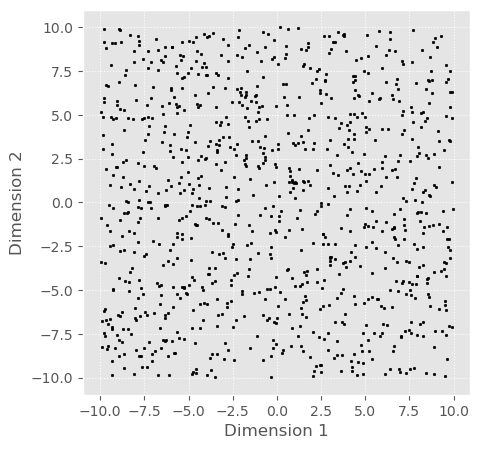

In [28]:
# Generate data
if DATASET_TYPE == 'uniformSquare':
    x = np.random.uniform(-10, 10, NUM_SAMPLES)
    y = np.random.uniform(-10, 10, NUM_SAMPLES)
    X = np.array([[xi, yi] for xi, yi in zip(x, y)])
elif DATASET_TYPE == 'uniformCube':
    x = np.random.uniform(-10, 10, NUM_SAMPLES)
    y = np.random.uniform(-10, 10, NUM_SAMPLES)
    z = np.random.uniform(-10, 10, NUM_SAMPLES)
    X = np.array([[xi, yi, zi] for xi, yi, zi in zip(x, y, z)])
elif DATASET_TYPE == 'blob':
    X, y_true = make_blobs(n_samples=NUM_SAMPLES, centers=1, cluster_std=30, random_state=0)
elif DATASET_TYPE == 'diabetes':
    diabetes = load_diabetes()
    X, y = diabetes.data, diabetes.target
    print(f"Features: {diabetes.feature_names}")
elif DATASET_TYPE == 'bnp':
    eleComb = 'PdPt'
    import pandas as pd
    with open(f"data/dfScaledNoLVHCs/dfScaledNoLVHC_{eleComb}_V1C99.pickle", 'rb') as f: 
        dfNormalised = pickle.load(f)
    # df = pd.read_csv('data/AuPd_nanoparticle_nonredundant_dataset.csv')
    X = dfNormalised.iloc[:, :-2].values
    print(f"Columns: {dfNormalised.columns}")

# Visualise data (plot first two dimensions)
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], s=3, c='k')
plt.grid(linestyle='dotted')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')

# Standardise data
sc = StandardScaler()
Xscaled = sc.fit_transform(X)

## General Functions

In [16]:
def plotAAoutputs(Xscaled, AAclassical, AAiterative,
                  plotSubsets=True, figName='',
                  figSize=(7, 4), dpi=300, verbose=False):
    """Plot the data and archetypes from both approaches."""
    Zclassical, Ziterative = AAclassical.archetypes, AAiterative.archetypes
    if verbose:
        print(f"Archetype set from classical approach:\n{Zclassical}")
        print(f"Archetype set from iterative approach:\n{Ziterative}")
    
    plt.figure(figsize=figSize, dpi=dpi)
    if not plotSubsets:
        plt.scatter(Xscaled[:, 0], Xscaled[:, 1], marker='.', s=5) # color='y', 
    else:
        for idxs in AAiterative.subsets_sample_idxs: 
            plt.scatter(Xscaled[idxs, 0], Xscaled[idxs, 1], marker='.', s=5)
    all_subsets_Zs =  np.concatenate(AAiterative.subsets_Zs, axis=1)
    plt.plot(Zclassical[0, :], Zclassical[1, :], 'X', markersize=9, markeredgecolor='k', markeredgewidth=0.8, color='r', alpha=0.5)  # color='m'
    plt.plot(Ziterative[0, :], Ziterative[1, :], 'X', markersize=9, markeredgecolor='k', markeredgewidth=0.8, color='b', alpha=0.5)  # color='c'
    plt.plot(all_subsets_Zs[0, :], all_subsets_Zs[1, :], 'D', markersize=4, markeredgecolor='k', markeredgewidth=0.6, color='y')  # color='b'
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.grid(linestyle='dotted')
    legendEntries = [f"Data Subset {i+1}" for i in range(len(AAiterative.subsets_sample_idxs))] if plotSubsets else ['Data']
    legendEntries += [f"Classical Approach Archetypes, ExpVar: {AAclassical.explained_variance_:.3f}", f"Iterative Approach Archetypes, ExpVar: {AAiterative.explained_variance_:.3f}", 'Archetypes from Split Sets']
    plt.legend(legendEntries, loc='center left', bbox_to_anchor=(1, 0.5), ncol=1, fancybox=True, shadow=False, fontsize='x-small')
    plt.tight_layout()
    plt.savefig(f"figures/AA_{figName}.png")

In [5]:
def runAAonData(Xscaled, numArchetypes=4, numSubsets=[4], onlyZ=False,
                robust=False, shuffle=True, randomState=42, 
                datasetType='uniformSquare', plotSubsets=True, 
                figSize=(7, 4), dpi=300, verbose=False):
    AAclassical = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=False, robust=robust, only_archetypes=onlyZ,
                                     C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                                     random_state=randomState, numThreads=NUM_JOBS)
    AAclassical.fit(Xscaled)
    if verbose:
        print(f"Classical archetypal analysis execution time: {AAclassical.run_time:.3f} s")
    # Elbow plot for iterative approach
    for (i, numSubset) in enumerate(numSubsets):
        AAiterative = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=True, robust=robust, only_archetypes=onlyZ, n_subsets=numSubset, shuffle=shuffle, 
                                         C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                                         random_state=randomState, numThreads=NUM_JOBS)
        AAiterative.fit(Xscaled)
        if verbose:
            print(f"Iterative archetypal analysis {numSubset} subsets execution time: {AAiterative.run_time:.3f} s")
        if not onlyZ:
            colourSubsetsStr = 'colourSubsets' if plotSubsets else 'colourWholeSet'
            plotAAoutputs(Xscaled, AAclassical, AAiterative,
                          plotSubsets=plotSubsets, figName=f"{datasetType}_{numSubset}-fold_{colourSubsetsStr}",
                          figSize=figSize, dpi=dpi, verbose=verbose)
    return AAclassical, AAiterative

### Visualise

In [9]:
X, y = make_regression(n_samples = 10000, n_features = 2, noise = 10, random_state = 42)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

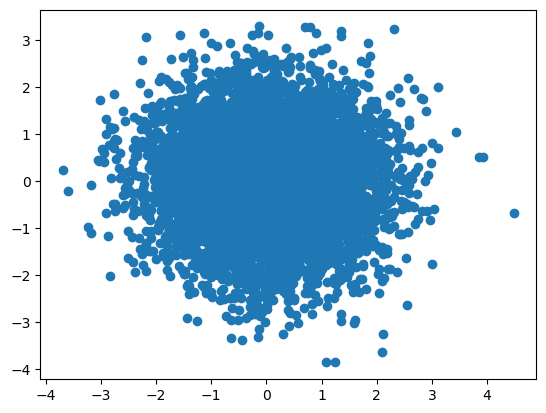

In [11]:
plt.scatter(pd.DataFrame(X_train)[0],pd.DataFrame(X_train)[1])
plt.show()

In [12]:
hull = ConvexHull(X_train)
X_hull = X_train[hull.vertices]
y_hull = y_train[hull.vertices]

<function matplotlib.pyplot.show(close=None, block=None)>

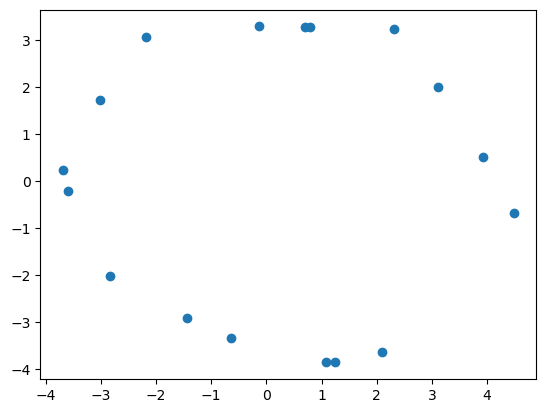

In [13]:
plt.scatter(pd.DataFrame(X_hull)[0],pd.DataFrame(X_hull)[1])
plt.show

In [14]:
model = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
model.fit(X_train, y_train)
model.score(X_test, y_test)

0.9900561543687222

In [15]:
model2 = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
model2.fit(X_hull, y_hull)
model2.score(X_test, y_test)

0.9897311952031062

In [17]:
model3 = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
model3.fit(X_train, y_train)
model3.score(X_test, y_test)

0.9869866795952289

In [18]:
model4 = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
model4.fit(X_hull, y_hull)
model4.score(X_test, y_test)

0.9725906524246746

For simple datasets, the hull performs slightly worse than the whole dataset with very limited data (18 in this case)

In [ ]:
#try different datasets

In [46]:
scores_full_lr = []
scores_hull_lr = []
scores_full_et = []
scores_hull_et = []
for n_features in range(2,10):
    X, y = make_regression(n_samples = 1000, n_features = n_features, noise = 10, random_state = 42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    hull = ConvexHull(X_train)
    X_hull = X_train[hull.vertices]
    y_hull = y_train[hull.vertices]
    
    model = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
    model.fit(X_train, y_train)
    scores_full_lr.append(model.score(X_test, y_test))
    model.fit(X_hull, y_hull)
    scores_hull_lr.append(model.score(X_test, y_test))
    
    model2 = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
    model2.fit(X_train, y_train)
    scores_full_et.append(model2.score(X_test, y_test))
    model2.fit(X_hull, y_hull)
    scores_hull_et.append(model2.score(X_test, y_test))

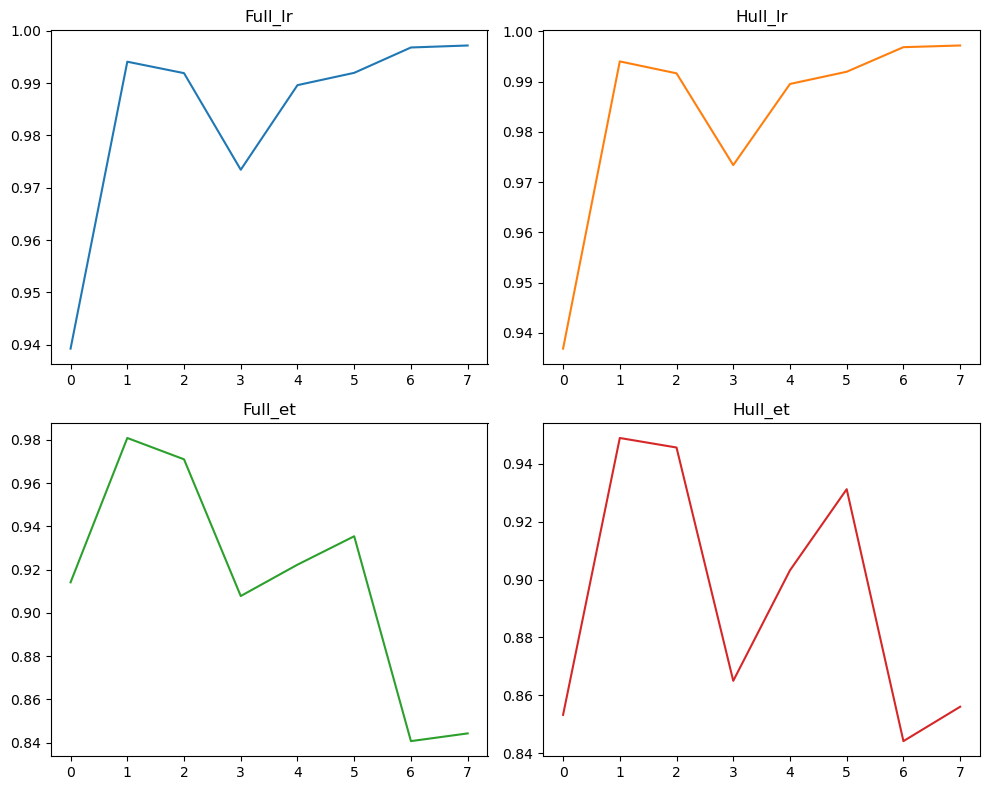

In [50]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs[0, 0].plot(scores_full_lr, 'tab:blue')
axs[0, 0].set_title('Full_lr')
axs[0, 1].plot(scores_hull_lr, 'tab:orange')
axs[0, 1].set_title('Hull_lr')
axs[1, 0].plot(scores_full_et, 'tab:green')
axs[1, 0].set_title('Full_et')
axs[1, 1].plot(scores_hull_et, 'tab:red')
axs[1, 1].set_title('Hull_et')
plt.tight_layout()
plt.show()

In [ ]:
#Try datasets that is not that linear

In [53]:
scores_full_lr = []
scores_hull_lr = []
scores_full_et = []
scores_hull_et = []
for n_features in range(2,10):
    X, y = make_regression(n_samples = 1000, n_features = n_features, noise = 100, random_state = 42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    hull = ConvexHull(X_train)
    X_hull = X_train[hull.vertices]
    y_hull = y_train[hull.vertices]
    
    model = RidgeCV(alphas=(0.01, 0.1, 1.0, 10.0, 100.0), fit_intercept=True, scoring=None, cv=None, gcv_mode='auto', store_cv_values=False, alpha_per_target=False)  
    model.fit(X_train, y_train)
    scores_full_lr.append(model.score(X_test, y_test))
    model.fit(X_hull, y_hull)
    scores_hull_lr.append(model.score(X_test, y_test))
    
    model2 = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
    model2.fit(X_train, y_train)
    scores_full_et.append(model2.score(X_test, y_test))
    model2.fit(X_hull, y_hull)
    scores_hull_et.append(model2.score(X_test, y_test))

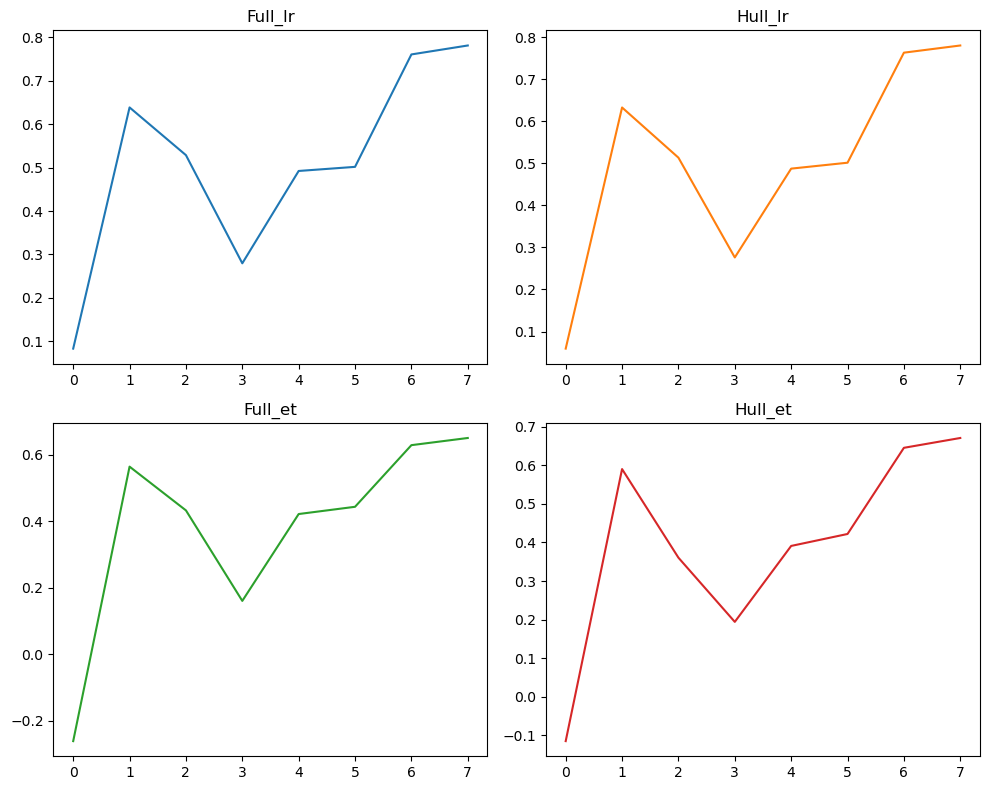

In [54]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs[0, 0].plot(scores_full_lr, 'tab:blue')
axs[0, 0].set_title('Full_lr')
axs[0, 1].plot(scores_hull_lr, 'tab:orange')
axs[0, 1].set_title('Hull_lr')
axs[1, 0].plot(scores_full_et, 'tab:green')
axs[1, 0].set_title('Full_et')
axs[1, 1].plot(scores_hull_et, 'tab:red')
axs[1, 1].set_title('Hull_et')
plt.tight_layout()
plt.show()

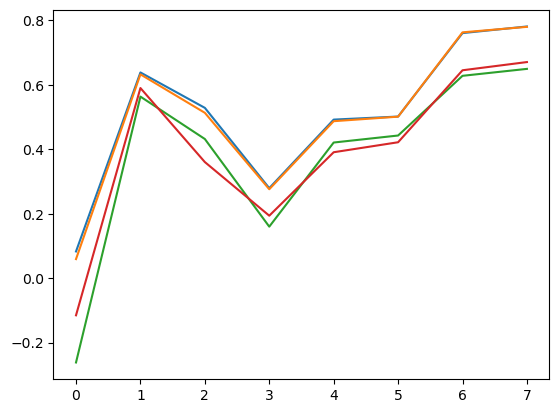

In [57]:
# They looked similar, so I put them together
plt.plot(scores_full_lr, 'tab:blue')
plt.plot(scores_hull_lr, 'tab:orange')
plt.plot(scores_full_et, 'tab:green')
plt.plot(scores_hull_et, 'tab:red')
plt.show()